# W12A · 변수변환 R 실습

먼저 결과를 예상하고 코드 본문을 수정한 뒤 계산값과 그림을 비교합니다. 수정하기 전과 뒤에 결과가 달라진 이유를 한 문장으로 적으세요. 실습 A와 B는 독립 실행됩니다.

## A1 · 차이와 비율을 먼저 계산

100→80→64의 두 차이와 두 비율을 먼저 적으세요. 아래 첫 표를 실행해 비교합니다. 다음 예제는 거듭제곱입니다. 처음에는 Y만 로그를 취합니다. 같은 A–D 점이 직선에 놓이도록 X축 함수 한 줄을 바꾸고, 기울기와 각 잔차가 어떻게 바뀌는지 확인하세요.

![A1 · 차이와 비율을 먼저 계산](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/course/notion/w12a/images/03-power.png)

[그림 원본](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/course/notion/w12a/images/03-power.png)
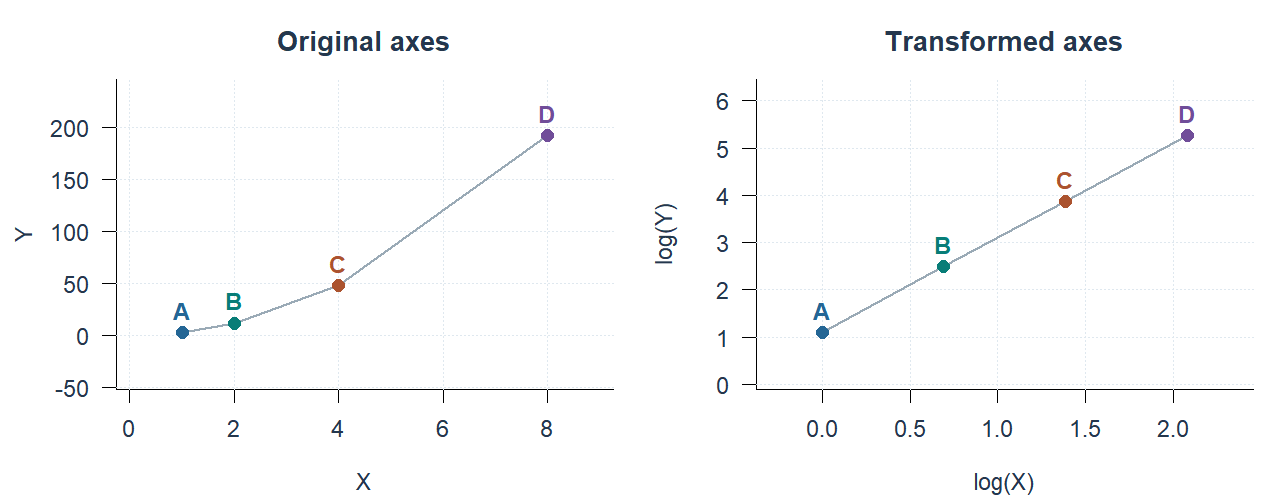

In [ ]:
step <- 0:3
count <- c(100, 80, 64, 51.2)
print(data.frame(from = step[-4], to = step[-1],
                 difference = diff(count), ratio = count[-1] / count[-4]))

# A1 편집: x축과 y축 중 어느 쪽에 log()를 넣을지 먼저 예측합니다.
x <- c(1, 2, 4, 8)
y <- 3 * x^2
axis_x <- function(x) x
axis_y <- function(y) log(y)
tx <- axis_x(x)
ty <- axis_y(y)
toy_slope <- sum((tx - mean(tx)) * (ty - mean(ty))) / sum((tx - mean(tx))^2)
toy <- lm(ty ~ tx)
print(data.frame(point = LETTERS[1:4], x, y, tx, ty, residual = residuals(toy)))
print(c(by_hand = toy_slope, by_lm = unname(coef(toy)[2])))
par(mfrow = c(1, 2))
plot(x, y, pch = 19, xlab = "X", ylab = "Y", main = "Original")
text(x, y, LETTERS[1:4], pos = 3)
plot(tx, ty, pch = 19, xlab = "Transformed X", ylab = "Transformed Y", main = "Edited axes")
abline(toy, col = "#A84231", lwd = 2)
text(tx, ty, LETTERS[1:4], pos = 3)
par(mfrow = c(1, 1))

## A2 · 정의역을 먼저 검사

R에서 0의 로그와 0·1의 로짓을 출력합니다. 열 usable이 FALSE인 위치를 예측하세요. 관측값을 임의로 더하거나 지우면 어떤 질문이 달라지는지 설명하세요. 다음으로 양수인 다른 벡터를 직접 만들어 검사하세요.

![A2 · 정의역을 먼저 검사](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/course/notion/w12a/images/03-logit.png)

[그림 원본](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/course/notion/w12a/images/03-logit.png)
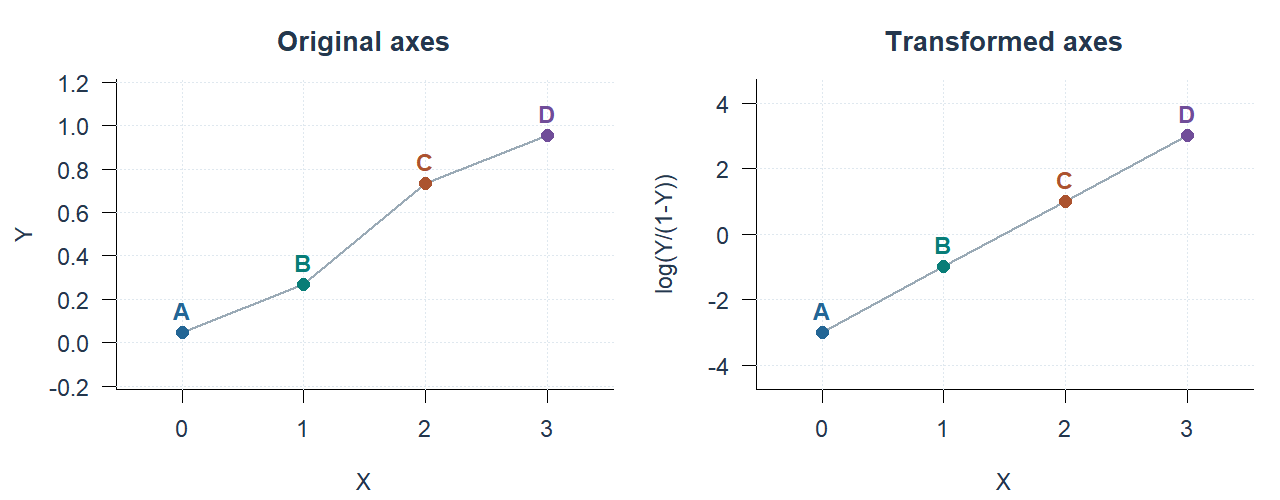

In [ ]:
# A2 편집: 0을 넣으면 어느 값이 유한하지 않을지 표시한 뒤 실행합니다.
log_input <- c(0, 1, 2, 4)
log_value <- suppressWarnings(log(log_input))
print(data.frame(log_input, log_value, usable = is.finite(log_value)))

fraction <- c(0, .25, .5, .75, 1)
odds <- fraction / (1 - fraction)
print(data.frame(fraction, odds, log_odds = log(odds),
                 usable = fraction > 0 & fraction < 1))

In [ ]:
stopifnot(all.equal(unname(diff(c(100,80,64))), c(-20,-16)),
          all.equal(c(80/100,64/80), c(.8,.8)),
          abs(coef(lm(log(3 * x^2) ~ log(x)))[2] - 2) < 1e-10,
          !is.finite(log(0)), !is.finite(qlogis(1)))
cat("W12A_A_OK\n")